# Hands-on-4: Perceptrón Multicapa (MLP) desde cero con Python

**Dataset:** Iris  
**Entorno:** Google Colab o Jupyter Notebook  
**Objetivo:** implementar una red neuronal multicapa sin utilizar bibliotecas de redes neuronales. Se usará **NumPy** para programar la red, sus operaciones matemáticas y la retropropagación. `scikit-learn` se empleará solo para cargar el dataset, dividirlo, escalarlo y calcular métricas.

## Pipeline de Machine Learning

1. Selección y descripción del dataset.
2. Visualización mediante un scatter plot.
3. Preprocesamiento: splitting y scaling.
4. Selección del modelo y entrenamiento.
5. Evaluación con accuracy y matriz de confusión.

> **¿Qué significa “from scratch”?** La arquitectura MLP, la propagación hacia adelante, la función de pérdida y la retropropagación del gradiente se programan manualmente. No se utilizan TensorFlow, Keras ni PyTorch.

## 1. Selección de los patrones para entrenamiento: dataset Iris

Iris es un conjunto de datos clásico que contiene **150 flores**, distribuidas en tres clases: *Iris setosa*, *Iris versicolor* e *Iris virginica*. Cada patrón contiene cuatro características numéricas:

- Longitud del sépalo.
- Ancho del sépalo.
- Longitud del pétalo.
- Ancho del pétalo.

La red aprenderá a clasificar una flor en una de las tres especies a partir de esas cuatro medidas.

In [1]:
# Importamos NumPy para realizar operaciones numéricas y manipular matrices.
import numpy as np

# Importamos pandas para mostrar el dataset en una tabla legible.
import pandas as pd

# Cargamos el dataset Iris incluido en scikit-learn.
from sklearn.datasets import load_iris

# Importamos las herramientas para dividir y escalar los datos.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Importamos las métricas que usaremos para evaluar las predicciones.
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# Importamos Matplotlib para construir gráficos.
import matplotlib.pyplot as plt

# Fijamos una semilla para que los resultados aleatorios sean reproducibles.
np.random.seed(42)

# Cargamos el conjunto de datos Iris.
iris = load_iris()

# X contiene las cuatro características numéricas de cada flor.
X = iris.data.astype(float)

# y contiene la clase correcta de cada flor, codificada como 0, 1 o 2.
y = iris.target.astype(int)

# Guardamos los nombres de las características y de las especies.
nombres_caracteristicas = iris.feature_names
nombres_clases = iris.target_names

# Creamos un DataFrame para inspeccionar los patrones.
df = pd.DataFrame(X, columns=nombres_caracteristicas)
df["especie"] = [nombres_clases[i] for i in y]

# Mostramos las primeras cinco filas del dataset.
display(df.head())

# Mostramos la cantidad de patrones, características y clases.
print("Dimensiones de X:", X.shape)
print("Cantidad de clases:", len(nombres_clases))
print("Clases:", nombres_clases)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dimensiones de X: (150, 4)
Cantidad de clases: 3
Clases: ['setosa' 'versicolor' 'virginica']


## 2. Scatter plot

El gráfico de dispersión permite observar la relación entre dos características. Aquí se representa la longitud del pétalo frente a su ancho, usando un color diferente para cada especie. Aunque el modelo recibirá las cuatro características, este gráfico bidimensional facilita la exploración visual.

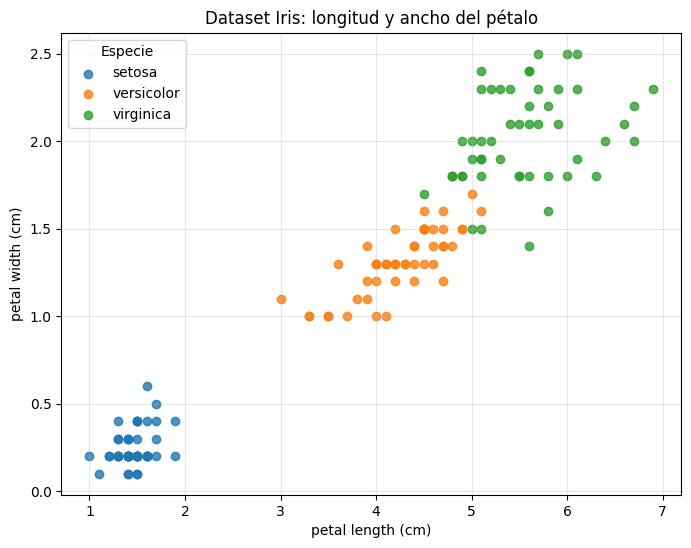

In [2]:
# Creamos una figura para visualizar longitud y ancho del pétalo.
plt.figure(figsize=(8, 6))

# Dibujamos los puntos de cada especie por separado para distinguirlas por color.
for clase_id, nombre_clase in enumerate(nombres_clases):
    # Seleccionamos las filas que pertenecen a la clase actual.
    mascara = y == clase_id

    # Graficamos la longitud del pétalo en el eje X y el ancho en el eje Y.
    plt.scatter(
        X[mascara, 2],
        X[mascara, 3],
        label=nombre_clase,
        alpha=0.8
    )

# Añadimos títulos y etiquetas para interpretar el gráfico.
plt.title("Dataset Iris: longitud y ancho del pétalo")
plt.xlabel(nombres_caracteristicas[2])
plt.ylabel(nombres_caracteristicas[3])
plt.legend(title="Especie")
plt.grid(True, alpha=0.3)

# Mostramos el gráfico.
plt.show()

## 3. Preprocesamiento del dataset

### 3.1 Splitting: entrenamiento y prueba

Se separa el dataset en **80 % para entrenamiento** y **20 % para prueba**. El parámetro `stratify=y` conserva aproximadamente la proporción de cada especie en ambos grupos.

### 3.2 Scaling: estandarización

Las características se estandarizan para que tengan una escala comparable. El escalador se ajusta **solo con los datos de entrenamiento** y luego se aplica a entrenamiento y prueba. Así se evita filtrar información del conjunto de prueba durante el preprocesamiento.

In [3]:
# Separamos los patrones en entrenamiento (80 %) y prueba (20 %).
# random_state permite reproducir la misma partición.
# stratify conserva la proporción de especies en ambos subconjuntos.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Creamos el objeto que estandarizará las características.
escalador = StandardScaler()

# Calculamos media y desviación estándar únicamente con los datos de entrenamiento.
X_train = escalador.fit_transform(X_train)

# Aplicamos al conjunto de prueba los parámetros aprendidos en entrenamiento.
X_test = escalador.transform(X_test)

# Mostramos las dimensiones para verificar la división.
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Mostramos los primeros cinco patrones ya estandarizados.
print("\nPrimeros patrones estandarizados:")
print(X_train[:5])

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)

Primeros patrones estandarizados:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


## 4. Selección del modelo y entrenamiento

Se implementará un MLP con esta arquitectura:

- **Capa de entrada:** 4 neuronas, una por característica.
- **Capa oculta:** 8 neuronas con activación ReLU.
- **Capa de salida:** 3 neuronas, una por especie, con softmax.

La red se entrenará con descenso de gradiente y retropropagación (*backpropagation*). La función de pérdida será la entropía cruzada. Los pesos se inicializan con valores pequeños aleatorios.

### Conceptos matemáticos

- **ReLU:** transforma los valores negativos en cero y conserva los positivos.
- **Softmax:** convierte los valores de salida en probabilidades cuya suma es 1.
- **Entropía cruzada:** mide el error entre las probabilidades predichas y las clases reales.
- **Retropropagación:** calcula cómo contribuye cada peso al error y permite actualizarlo.

In [4]:
# Define ReLU, la función de activación de la capa oculta.
def relu(z):
    # Conserva los valores positivos y convierte los negativos en cero.
    return np.maximum(0, z)


# Define la derivada de ReLU, necesaria para calcular los gradientes.
def relu_derivada(z):
    # La derivada vale 1 cuando z es positivo y 0 en caso contrario.
    return (z > 0).astype(float)


# Convierte las puntuaciones de salida en probabilidades por clase.
def softmax(z):
    # Restamos el máximo de cada fila para mejorar la estabilidad numérica.
    z_estable = z - np.max(z, axis=1, keepdims=True)

    # Calculamos la exponencial de cada puntuación.
    exp_z = np.exp(z_estable)

    # Normalizamos cada fila para que las probabilidades sumen 1.
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


# Convierte las etiquetas 0, 1 y 2 en vectores one-hot.
def one_hot(y, numero_clases):
    # Cada fila tendrá un 1 en la posición correspondiente a la clase correcta.
    return np.eye(numero_clases)[y]


# Implementa un perceptrón multicapa usando solamente operaciones de NumPy.
class MLP:
    def __init__(self, numero_entradas, neuronas_ocultas, numero_clases, tasa_aprendizaje=0.05):
        # Guardamos la tasa de aprendizaje, que controla el tamaño de cada actualización.
        self.tasa_aprendizaje = tasa_aprendizaje

        # Inicializamos los pesos de entrada a capa oculta con valores aleatorios pequeños.
        self.W1 = np.random.randn(numero_entradas, neuronas_ocultas) * np.sqrt(2 / numero_entradas)

        # Inicializamos en cero los sesgos de la capa oculta.
        self.b1 = np.zeros((1, neuronas_ocultas))

        # Inicializamos los pesos que conectan la capa oculta con la salida.
        self.W2 = np.random.randn(neuronas_ocultas, numero_clases) * np.sqrt(2 / neuronas_ocultas)

        # Inicializamos en cero los sesgos de la capa de salida.
        self.b2 = np.zeros((1, numero_clases))

    def forward(self, X):
        # Calculamos la combinación lineal que entra en la capa oculta.
        self.z1 = X @ self.W1 + self.b1

        # Aplicamos ReLU para obtener las activaciones ocultas.
        self.a1 = relu(self.z1)

        # Calculamos las puntuaciones de la capa de salida.
        self.z2 = self.a1 @ self.W2 + self.b2

        # Aplicamos softmax para obtener probabilidades por especie.
        self.a2 = softmax(self.z2)

        # Devolvemos las probabilidades calculadas.
        return self.a2

    def calcular_perdida(self, probabilidades, y_real):
        # Transformamos las etiquetas reales a formato one-hot.
        y_codificado = one_hot(y_real, probabilidades.shape[1])

        # Limitamos las probabilidades para evitar calcular logaritmo de cero.
        probabilidades_seguras = np.clip(probabilidades, 1e-12, 1.0)

        # Calculamos la entropía cruzada promedio del conjunto.
        perdida = -np.mean(np.sum(y_codificado * np.log(probabilidades_seguras), axis=1))

        # Regresamos el valor de pérdida.
        return perdida

    def backward(self, X, y_real):
        # Obtenemos la cantidad de patrones de entrenamiento.
        m = X.shape[0]

        # Codificamos las clases reales como vectores one-hot.
        y_codificado = one_hot(y_real, self.a2.shape[1])

        # Calculamos el gradiente de la salida para softmax y entropía cruzada.
        dz2 = (self.a2 - y_codificado) / m

        # Calculamos los gradientes de los pesos y sesgos de salida.
        dW2 = self.a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        # Propagamos el error hacia las activaciones de la capa oculta.
        da1 = dz2 @ self.W2.T

        # Aplicamos la derivada de ReLU para obtener el gradiente de z1.
        dz1 = da1 * relu_derivada(self.z1)

        # Calculamos los gradientes de los pesos y sesgos de la capa oculta.
        dW1 = X.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        # Actualizamos los pesos restando la tasa de aprendizaje por el gradiente.
        self.W2 -= self.tasa_aprendizaje * dW2
        self.b2 -= self.tasa_aprendizaje * db2
        self.W1 -= self.tasa_aprendizaje * dW1
        self.b1 -= self.tasa_aprendizaje * db1

    def fit(self, X, y, epocas=1000, imprimir_cada=100):
        # Creamos una lista para guardar la pérdida de cada época.
        historial_perdida = []

        # Cada época realiza una pasada completa por los patrones de entrenamiento.
        for epoca in range(1, epocas + 1):
            # Ejecutamos la propagación hacia adelante para obtener probabilidades.
            probabilidades = self.forward(X)

            # Calculamos la pérdida antes de actualizar los parámetros.
            perdida = self.calcular_perdida(probabilidades, y)
            historial_perdida.append(perdida)

            # Calculamos los gradientes y actualizamos pesos y sesgos.
            self.backward(X, y)

            # Mostramos el progreso al inicio y cada cierto número de épocas.
            if epoca == 1 or epoca % imprimir_cada == 0:
                print(f"Época {epoca:4d} | Pérdida: {perdida:.4f}")

        # Devolvemos el historial para analizar el aprendizaje.
        return historial_perdida

    def predict_proba(self, X):
        # Calculamos las probabilidades de cada clase para los patrones recibidos.
        return self.forward(X)

    def predict(self, X):
        # Elegimos la clase que tenga la probabilidad más alta.
        return np.argmax(self.predict_proba(X), axis=1)

Época    1 | Pérdida: 1.5358
Época  100 | Pérdida: 0.3625
Época  200 | Pérdida: 0.2434
Época  300 | Pérdida: 0.1863
Época  400 | Pérdida: 0.1490
Época  500 | Pérdida: 0.1230
Época  600 | Pérdida: 0.1014
Época  700 | Pérdida: 0.0887
Época  800 | Pérdida: 0.0804
Época  900 | Pérdida: 0.0740
Época 1000 | Pérdida: 0.0688


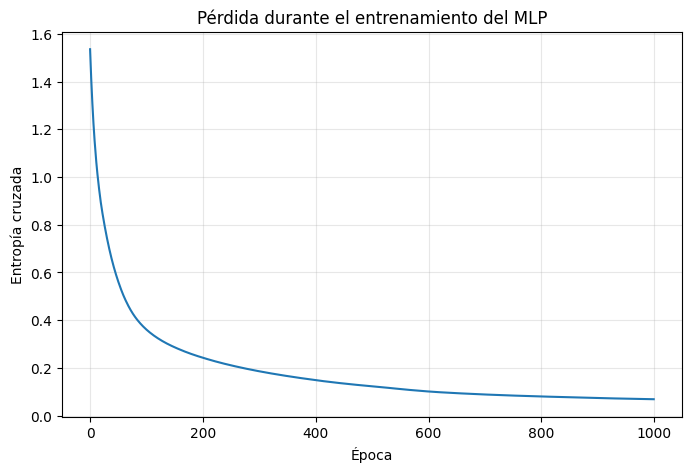

In [5]:
# Creamos el MLP con 4 entradas, 8 neuronas ocultas y 3 salidas.
modelo = MLP(
    numero_entradas=X_train.shape[1],
    neuronas_ocultas=8,
    numero_clases=len(nombres_clases),
    tasa_aprendizaje=0.05
)

# Entrenamos la red durante 1000 épocas y guardamos la pérdida.
historial_perdida = modelo.fit(
    X_train,
    y_train,
    epocas=1000,
    imprimir_cada=100
)

# Graficamos cómo cambia la pérdida durante el entrenamiento.
plt.figure(figsize=(8, 5))
plt.plot(historial_perdida)
plt.title("Pérdida durante el entrenamiento del MLP")
plt.xlabel("Época")
plt.ylabel("Entropía cruzada")
plt.grid(True, alpha=0.3)
plt.show()

## 5. Evaluación del modelo

Una vez entrenada la red, se evalúa con los patrones de prueba, que no se utilizaron para actualizar los pesos.

- **Accuracy:** proporción de predicciones correctas sobre el total de ejemplos de prueba.
- **Matriz de confusión:** las filas representan las clases reales y las columnas las clases predichas. La diagonal contiene las predicciones correctas; los valores fuera de la diagonal representan errores.

Accuracy en prueba: 0.9333 (93.33 %)

Reporte de clasificación:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



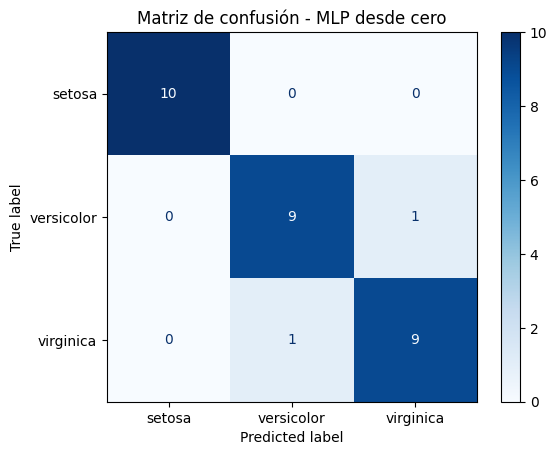

Matriz de confusión:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [6]:
# Predecimos las clases del conjunto de prueba, que no se usó para entrenar.
y_pred = modelo.predict(X_test)

# Calculamos accuracy: predicciones correctas divididas entre el total de predicciones.
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy en prueba: {accuracy:.4f} ({accuracy * 100:.2f} %)")

# Mostramos precisión, recall y F1-score por especie como métricas complementarias.
print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred,
    target_names=nombres_clases,
    zero_division=0
))

# Calculamos la matriz de confusión usando el orden fijo de las tres clases.
matriz = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

# Dibujamos la matriz para comparar clases reales y clases predichas.
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=nombres_clases
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - MLP desde cero")
plt.show()

# Imprimimos la matriz como números para facilitar su lectura.
print("Matriz de confusión:")
print(matriz)

## 6. Interpretación de resultados y conclusión

Análisis de resultados

El desempeño del modelo se analiza mediante el accuracy, que indica la proporción de clasificaciones correctas, y la matriz de confusión, que permite identificar las especies clasificadas correctamente y los posibles errores de predicción.

Conclusión

El desarrollo de este MLP permite comprender el proceso de entrenamiento de una red neuronal multicapa desde cero, utilizando Python y NumPy. Mediante el dataset Iris, se busca clasificar tres especies de flores a partir de sus características, evaluando el desempeño del modelo con las métricas obtenidas durante la ejecución.